# BÁO CÁO PHẦN 2 - BÀI 6 (TRANG 45): GROCERIES DATASET (MARKET BASKET ANALYSIS)
## CÂU 6: Biểu đồ so sánh thời gian thực thi và Nhận xét, Giải thích nguyên nhân
- Vẽ biểu đồ đường (Line Chart) biểu diễn thời gian thực thi theo từng ngưỡng $min\_sup$
- Đưa ra nhận xét chi tiết và phân tích sâu về nguyên nhân kỹ thuật


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016


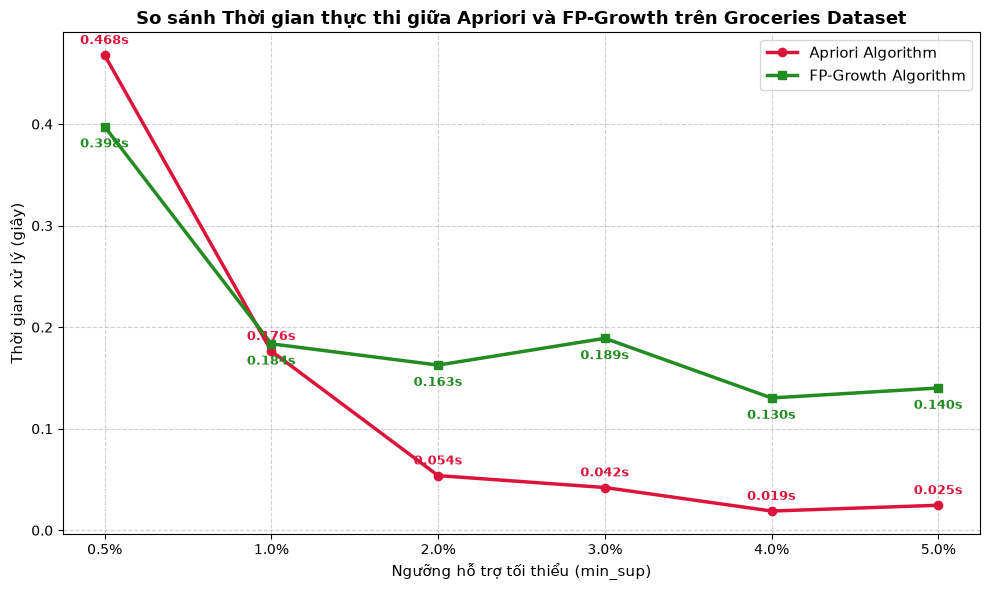

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)

import time

path = get_data_path('groceries.csv')
with open(path, 'r', encoding='utf-8') as f:
    transactions = [line.strip().split(',') for line in f if line.strip()]

te = TransactionEncoder()
df_groceries = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

thresholds = [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]
times_ap = []
times_fp = []
itemset_counts = []

for s in thresholds:
    t0 = time.time()
    it_ap = apriori(df_groceries, min_support=s, use_colnames=True)
    times_ap.append(time.time() - t0)
    itemset_counts.append(len(it_ap))
    
    t0 = time.time()
    it_fp = fpgrowth(df_groceries, min_support=s, use_colnames=True)
    times_fp.append(time.time() - t0)

# Vẽ biểu đồ so sánh thời gian
plt.figure(figsize=(10, 6))
labels = [f"{s*100:.1f}%" for s in thresholds]

plt.plot(labels, times_ap, marker='o', linewidth=2.5, color='crimson', label='Apriori Algorithm')
plt.plot(labels, times_fp, marker='s', linewidth=2.5, color='forestgreen', label='FP-Growth Algorithm')

plt.title("So sánh Thời gian thực thi giữa Apriori và FP-Growth trên Groceries Dataset", fontsize=13, fontweight='bold')
plt.xlabel("Ngưỡng hỗ trợ tối thiểu (min_sup)", fontsize=11)
plt.ylabel("Thời gian xử lý (giây)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)

for i in range(len(labels)):
    plt.annotate(f"{times_ap[i]:.3f}s", (labels[i], times_ap[i]), textcoords="offset points", xytext=(0,8), ha='center', color='crimson', fontsize=9, fontweight='bold')
    plt.annotate(f"{times_fp[i]:.3f}s", (labels[i], times_fp[i]), textcoords="offset points", xytext=(0,-15), ha='center', color='forestgreen', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Nhận xét & Giải thích Chuyên sâu:
1. **Nhận xét đồ thị:**
   - Khi $min\_sup$ ở mức cao ($\ge 3\%$), số lượng tập mục phổ biến ít, cả hai thuật toán đều thực thi rất nhanh (dưới 0.05 giây).
   - Khi $min\_sup$ giảm dần xuống $1\%$ và $0.5\%$, đồ thị thời gian của **Apriori tăng dốc đứng**, trong khi đường thời gian của **FP-Growth tăng mượt và ổn định hơn rất nhiều**.

2. **Giải thích nguyên nhân cốt lõi về thuật toán:**
   - **Nhược điểm của Apriori:**
     * *Sinh tập ứng viên bùng nổ tổ hợp ($O(2^d)$)*: Để tìm tập $k$-mục phổ biến, Apriori phải kết nối và sinh toàn bộ các tập ứng viên $C_k$ từ $L_{k-1}$. Khi $min\_sup$ nhỏ, số lượng ứng viên sinh ra là khổng lồ.
     * *Quét CSDL lặp lại nhiều lần*: Với mỗi cấp $k$, Apriori phải quét lại toàn bộ CSDL 9.835 giao dịch để đếm tần suất xuất hiện của từng ứng viên. Chi phí I/O và duyệt dữ liệu cực lớn.
   - **Ưu điểm vượt trội của FP-Growth:**
     * *Chỉ quét CSDL đúng 2 lần*: Lần 1 để đếm tần suất các 1-itemset và sắp xếp theo thứ tự giảm dần; Lần 2 để xây dựng toàn bộ cấu trúc cây tiền tố **FP-Tree** trong bộ nhớ.
     * *Không cần sinh tập ứng viên (No Candidate Generation)*: FP-Growth khai phá trực tiếp trên cây FP-Tree bằng cách xây dựng các cây điều kiện (Conditional FP-Tree) và cơ sở mẫu điều kiện đệ quy từ dưới lên.
     * *Nén dữ liệu cao*: Các giao dịch có chung tiền tố sẽ được chia sẻ cùng các nút trên cây, giúp tiết kiệm bộ nhớ và đẩy nhanh tốc độ duyệt.
